# Notebook 05 — Model Selection, Stage A

**Project:** A Multi-Modal Deep Learning Approach for Eggshell Micro-Crack Morphology Analysis and Root-Cause Diagnosis in Poultry Breeder Farms
**Author:** M.P.N. Sharindi (Coventry Index 16110429)
**Stage:** 05 of 12 — Stage A of three

---

### The bar this notebook has to clear

Notebooks 01b to 04 established the numbers every model result must be read against. They are not
chance level.

| | four-class macro F1 | binary macro F1 |
|---|---|---|
| majority class | 0.164 | 0.339 |
| **acquisition floor** (capture statistics, no pixels) | **0.357** | **0.666** |
| best classical pipeline (texture + ridge + geometry) | **0.565** | **0.770** |
| the same under session-grouped evaluation | 0.473 | 0.662 |
| human-polygon oracle (not deployable) | 0.829 | — |

A convolutional network that reaches 0.70 on binary detection has beaten the acquisition floor by
0.03 and lost to a logistic regression on Gabor filters. **The target is 0.565 and 0.770**, and to
count as an improvement the margin must exceed the fold standard deviation.

The gap between the oracle at 0.829 and the best deployable classical pipeline at 0.565 is 0.264,
and notebook 04 showed why: a classical ridge detector recovers under 3 % of the annotated crack
area, because shell mottling and the egg rim produce ridge responses as strong as the cracks. The
hard part of this problem is **locating** the crack. That is the evidence for formulation (d),
which supervises the backbone with the 335 annotation polygons, and it is why (d) is treated here
as a leading contender rather than an optional extra.

### Staged protocol

Running every backbone against every formulation across five folds is over a hundred training runs,
which the 6 GB RTX 3050 cannot deliver in reasonable time. Three stages instead, each narrowing the
field. This notebook is Stage A.

| Stage | What runs | Runs | Estimate |
|---|---|---|---|
| **A (this notebook)** | five backbones, formulation (b), five folds | 25 | 4–7 h |
| B | top two backbones, four formulations, five folds | up to 40 | 6–10 h |
| C | best combination: imbalance strategy, augmentation policy, resolution, plus the crack-masked control | ~20 | 3–5 h |

Every run appends to `results/runs.csv` the moment it finishes and checkpoints per fold, so an
interrupted overnight session resumes where it stopped rather than restarting.

### Run the smoke test first

Section 2 trains two formulations for two epochs on 48 images. It takes about a minute and exercises
every code path the overnight run depends on: the cache reader, the mask rasteriser, mixed
precision, gradient accumulation, the multi-task heads and the segmentation decoder. **Send me its
output before starting Stage A.** Finding a bug after four hours of GPU time is avoidable.

---
## 0. Configuration

In [1]:
import os
os.environ["EGG_ARTEFACT_ROOT"] = r"D:\Eggshell-Diagnostic-Research\Artefact"

RUN_SMOKE_TEST = False      # always run this first
RUN_STAGE_A    = True     # flip to True once the smoke test passes

CACHE_VARIANT  = "neutral_fill"
CACHE_SIDE     = 448
TRAIN_SIDE     = 384
POLICY         = "medium"  # adopted in notebook 03; 'light' is ablated in Stage C

BACKBONES_A    = ["mobilenetv3", "efficientnet_b0", "resnet18", "convnext_tiny", "vit_small"]
EPOCHS         = 30
EFFECTIVE_BATCH = 32       # held constant so every backbone gets the same optimisation budget
# Measured in the smoke test: EfficientNet-B0 at 384 px used 1.16 GB at physical batch 8, i.e.
# about 107 MB of activations per sample on top of ~0.3 GB of weights and optimiser state. Batch
# 32 therefore lands near 3.7 GB, comfortably inside 6.4 GB, and needs no gradient accumulation
# at all for the smaller backbones. If any of these do run out of memory the loop halves the
# batch and retries rather than dropping the backbone.
PHYSICAL_BATCH = {
    "mobilenetv3": 32, "efficientnet_b0": 32, "resnet18": 32,
    "convnext_tiny": 16, "vit_small": 16,
}
NUM_WORKERS    = 4         # Windows spawns worker processes; 4 keeps the GPU fed without
                           # duplicating large arrays eight times in RAM. Set to 0 if it hangs.
PATIENCE       = 8
RUN_TIME_PROBE = False     # measure before committing to the overnight run
CHANNELS_LAST  = True
STAGE_A_FOLDS  = 3         # screen on 3 folds; the full 5 are used in Stage B on the top two
STAGE_A_BUDGET_HOURS = 7.0 # what you are willing to spend overnight

In [2]:
import sys, json, math, time, warnings, platform
from pathlib import Path
from datetime import datetime

_here = Path.cwd()
_src = next((p / "src" for p in [_here, *_here.parents] if (p / "src" / "common").is_dir()), None)
if _src is None:
    raise RuntimeError("Run from Artefact/notebooks/ or set EGG_ARTEFACT_ROOT.")
sys.path.insert(0, str(_src))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from common import project_config as CFG
from common.data import EggDataset, build_crack_masks, make_loader, class_weights
from common.engine import TrainConfig, train_fold, predict, append_run
from common.models import BACKBONES, SEG_CAPABLE

warnings.filterwarnings("ignore")
CFG.seed_everything()

STAGE = "05_model_selection"
OUT = CFG.results_dir(STAGE); FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
PROC = CFG.DATA_DIR / "processed"
CKPT = CFG.MODELS_DIR / "stage_a"; CKPT.mkdir(parents=True, exist_ok=True)
RUNS_CSV = CFG.RESULTS_DIR / "runs.csv"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("=" * 68)
print(f"torch {torch.__version__} | cuda {torch.version.cuda} | device {device}")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"gpu   {p.name}  {p.total_memory / 1e9:.1f} GB")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: no GPU visible. Stage A will take days on CPU. Fix this before continuing.")
try:
    import timm
    print(f"timm  {timm.__version__}")
except ImportError:
    raise ImportError("timm is required. Install with: pip install timm")
print("=" * 68)

torch 2.14.1+cpu | cuda None | device cpu
timm  1.0.30


In [3]:
splits = pd.read_csv(PROC / "splits.csv")
splits["label4"] = pd.Categorical(splits["label4"], categories=CFG.LABEL4, ordered=True)
CACHE_PATH = PROC / f"cache_{CACHE_VARIANT}_{CACHE_SIDE}.npy"

# --- label vectors, indexed by cache row ---------------------------------
y4 = splits["label4"].map(CFG.LABEL4_TO_IDX).to_numpy(dtype=np.int64)
y2 = splits["is_cracked"].to_numpy(dtype=np.int64)
# pattern index for cracked eggs; -100 makes cross-entropy ignore intact eggs
ypat = np.where(y4 > 0, y4 - 1, -100).astype(np.int64)
age = splits["age_class"].map(CFG.AGE_TO_IDX).to_numpy(dtype=np.int64)
LABELS = {"y4": y4, "y2": y2, "ypat": ypat, "age": age}

print("rasterising annotation polygons ...")
MASKS = build_crack_masks(splits["crack_region"].tolist(), TRAIN_SIDE)
print(f"masks {MASKS.shape}, {MASKS.nbytes / 1e6:.0f} MB, "
      f"{int((MASKS.sum(axis=(1, 2)) > 0).sum())} eggs carry a crack mask")

dev_rows = splits.index[splits["split"].eq("dev")].to_numpy()
folds = splits["fold"].to_numpy()
print(f"development {len(dev_rows)} eggs | test {int((splits['split'] == 'test').sum())} (sealed)")
print("the test set is NOT used anywhere in this notebook")

TARGETS = {"acquisition_floor_4class": 0.357, "acquisition_floor_binary": 0.666,
           "best_classical_4class": 0.565, "best_classical_binary": 0.770,
           "oracle_4class": 0.829}


def fold_rows(k):
    tr = splits.index[(splits["split"].eq("dev")) & (splits["fold"] != k)].to_numpy()
    va = splits.index[(splits["split"].eq("dev")) & (splits["fold"] == k)].to_numpy()
    return tr, va


def build_loaders(cfg: TrainConfig, tr_rows, va_rows, want_mask: bool, batch: int,
                  workers: int):
    masks = MASKS if want_mask else None
    ds_tr = EggDataset(CACHE_PATH, tr_rows, LABELS, cfg.train_side, policy=cfg.policy,
                       masks=masks, occlude_crack=cfg.occlude_crack)
    ds_va = EggDataset(CACHE_PATH, va_rows, LABELS, cfg.train_side, policy=None,
                       masks=masks, occlude_crack=cfg.occlude_crack)
    bal = cfg.imbalance == "balanced_sampler"
    ltr = make_loader(ds_tr, batch, True, workers, balanced=bal, y_for_balance=y4,
                      seed=cfg.seed)
    lva = make_loader(ds_va, batch, False, workers)
    return ltr, lva


def weights_for(cfg: TrainConfig, tr_rows):
    if cfg.imbalance != "class_weights":
        return None, None, None
    return (class_weights(y4[tr_rows], 4), class_weights(y2[tr_rows], 2),
            class_weights(ypat[tr_rows][ypat[tr_rows] >= 0], 3))

rasterising annotation polygons ...
masks (652, 384, 384), 96 MB, 335 eggs carry a crack mask
development 554 eggs | test 98 (sealed)
the test set is NOT used anywhere in this notebook


---
## 2. Smoke test

Two epochs on 48 eggs. This is not a result — it exercises every code path the overnight run
depends on, so that a bug surfaces in a minute rather than after four hours of GPU time.

Formulation (d) is included deliberately. It is the only one that touches the segmentation decoder
and the mask pipeline, and therefore the one most likely to break.

In [4]:
if RUN_SMOKE_TEST:
    rng = np.random.default_rng(0)
    # a small stratified sample so every class is present
    smoke_rows = np.concatenate([
        rng.choice(splits.index[(splits["split"].eq("dev")) & (splits["label4"].eq(c))].to_numpy(),
                   size=12, replace=False) for c in CFG.LABEL4])
    tr_s, va_s = smoke_rows[:32], smoke_rows[32:]
    print(f"smoke set: {len(tr_s)} train / {len(va_s)} val\n")

    for form, n_out, back in [("single4", 4, "efficientnet_b0"),
                              ("multitask_seg", 4, "efficientnet_b0")]:
        print(f"--- {form} on {back} ---")
        t0 = time.time()
        cfg = TrainConfig(backbone=back, formulation=form, n_out=n_out, policy=POLICY,
                          train_side=TRAIN_SIDE, epochs=2, physical_batch=8,
                          effective_batch=16, patience=99, num_workers=0, tag="smoke")
        want_mask = form == "multitask_seg"
        ltr, lva = build_loaders(cfg, tr_s, va_s, want_mask, 8, 0)
        b = next(iter(ltr))
        print(f"  batch: image {tuple(b['image'].shape)} {b['image'].dtype}  "
              f"mean {b['image'].mean():.3f} sd {b['image'].std():.3f}"
              + (f"  mask {tuple(b['mask'].shape)} frac {b['mask'].mean():.4f}"
                 if 'mask' in b else ""))
        w4, w2, wp = weights_for(cfg, tr_s)
        best, hist, _ = train_fold(cfg, ltr, lva, device, w4, w2, wp, verbose=True)
        print(f"  OK in {time.time() - t0:.0f}s | peak VRAM {best['peak_vram_gb']:.2f} GB | "
              f"params {best['params_m']:.1f}M\n")

    print("SMOKE TEST PASSED — every code path works. Send this output before running Stage A.")
else:
    print("smoke test skipped")

smoke test skipped


---
## 2b. Timing probe

The first version of this probe divided total elapsed time by two epochs, which charged model
construction, pretrained-weight download, Windows DataLoader worker spawn and cuDNN autotuning to
the per-epoch figure. It reported 85 hours for Stage A. Those are one-off costs, not per-epoch
costs, and dividing them by two inflated everything.

The probe now measures two separate things:

**A raw GPU benchmark** on synthetic tensors, timed after a warm-up and with explicit CUDA
synchronisation, bypassing the DataLoader entirely. This is what the hardware can do and it
isolates the GPU from the input pipeline.

**Steady-state epoch time**, taken from the last epoch of a short real run, so one-off setup is
amortised away rather than divided by two.

If the two disagree sharply, the bottleneck is the input pipeline, not the GPU, and the fix is
`NUM_WORKERS` rather than a smaller backbone.

In [5]:
from common.models import build_model
from common.engine import amp_autocast, make_scaler

def gpu_benchmark(backbone, batch, side=TRAIN_SIDE, warmup=3, iters=10):
    """Forward + backward on synthetic data. Pure GPU throughput, no data loading."""
    model = build_model(backbone, "single4", 4, pretrained=False, img_size=side).to(device)
    if CHANNELS_LAST:
        model = model.to(memory_format=torch.channels_last)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4)
    scaler = make_scaler(True)
    x = torch.randn(batch, 3, side, side, device=device)
    if CHANNELS_LAST:
        x = x.to(memory_format=torch.channels_last)
    y = torch.randint(0, 4, (batch,), device=device)
    torch.cuda.reset_peak_memory_stats()

    def step():
        opt.zero_grad(set_to_none=True)
        with amp_autocast(True):
            loss = F.cross_entropy(model(x)["logits"], y)
        if scaler is not None:
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        else:
            loss.backward(); opt.step()

    for _ in range(warmup):
        step()
    torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(iters):
        step()
    torch.cuda.synchronize()
    dt = time.time() - t0
    vram = torch.cuda.max_memory_allocated() / 1e9
    del model, opt, x, y
    torch.cuda.empty_cache()
    return batch * iters / dt, vram


if RUN_TIME_PROBE:
    n_train = int(((splits["split"] == "dev") & (splits["fold"] != 0)).sum())
    n_val = int(((splits["split"] == "dev") & (splits["fold"] == 0)).sum())
    print(f"per fold: {n_train} train + {n_val} val images\n")
    print("--- raw GPU throughput (synthetic data, no DataLoader) ---")
    rows = []
    for back in BACKBONES_A:
        batch = PHYSICAL_BATCH.get(back, 8)
        try:
            ips, vram = gpu_benchmark(back, batch)
            est_ep = (n_train + n_val * 0.4) / ips     # validation is forward-only, ~40% the cost
            rows.append({"backbone": back, "batch": batch, "img_per_s": round(ips, 1),
                         "peak_vram_gb": round(vram, 2),
                         "gpu_sec_per_epoch": round(est_ep, 1),
                         "est_hours_5folds": round(est_ep * EPOCHS * 5 / 3600, 2)})
            print(f"  {back:<16s} {ips:>6.1f} img/s  {vram:.2f} GB  "
                  f"-> {est_ep:>5.1f}s/epoch  {rows[-1]['est_hours_5folds']:>5.2f} h for 5 folds")
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            rows.append({"backbone": back, "batch": batch, "img_per_s": np.nan,
                         "peak_vram_gb": np.nan, "gpu_sec_per_epoch": np.nan,
                         "est_hours_5folds": np.nan, "note": f"OOM at batch {batch}"})
            print(f"  {back:<16s} OUT OF MEMORY at batch {batch}")
        except Exception as ex:
            torch.cuda.empty_cache()
            rows.append({"backbone": back, "batch": batch, "img_per_s": np.nan,
                         "peak_vram_gb": np.nan, "gpu_sec_per_epoch": np.nan,
                         "est_hours_5folds": np.nan, "note": f"{type(ex).__name__}: {ex}"})
            print(f"  {back:<16s} FAILED -- {type(ex).__name__}: {ex}")
    probe = pd.DataFrame(rows).set_index("backbone")
    probe.to_csv(TAB_DIR / "t00_timing_probe.csv")
else:
    probe = None
    print("timing probe skipped")

timing probe skipped


In [6]:
if RUN_TIME_PROBE and probe is not None:
    # --- steady-state check on the real pipeline, for the fastest usable backbone
    ok = probe["img_per_s"].notna()
    ref = probe.loc[ok, "gpu_sec_per_epoch"].idxmin() if ok.any() else None
    if ref is not None:
        print(f"\n--- real pipeline, 3 epochs on {ref}, steady state from the last epoch ---")
        tr, va = fold_rows(0)
        cfg = TrainConfig(backbone=ref, formulation="single4", n_out=4, policy=POLICY,
                          train_side=TRAIN_SIDE, epochs=3,
                          physical_batch=PHYSICAL_BATCH.get(ref, 16),
                          effective_batch=EFFECTIVE_BATCH, patience=99,
                          num_workers=NUM_WORKERS, tag="probe")
        t_setup = time.time()
        ltr, lva = build_loaders(cfg, tr, va, False, cfg.physical_batch, NUM_WORKERS)
        w4, w2, wp = weights_for(cfg, tr)
        setup_s = time.time() - t_setup
        _, hist, _ = train_fold(cfg, ltr, lva, device, w4, w2, wp, verbose=False)
        eps = [h["epoch_seconds"] for h in hist]
        steady = eps[-1]
        print(f"  epoch times: {[round(e, 1) for e in eps]}")
        print(f"  loader setup {setup_s:.1f}s | first epoch {eps[0]:.1f}s | steady {steady:.1f}s")
        gpu_only = float(probe.loc[ref, "gpu_sec_per_epoch"])
        print(f"  GPU-only estimate {gpu_only:.1f}s vs measured {steady:.1f}s")
        if steady > gpu_only * 1.6:
            print("  -> the INPUT PIPELINE is the bottleneck, not the GPU. Raise NUM_WORKERS")
            print("     (try 6 or 8) before reducing the backbone list.")
        else:
            print("  -> the GPU is the bottleneck; the estimates below are realistic.")
        scale = steady / max(gpu_only, 1e-6)
        probe["real_sec_per_epoch"] = (probe["gpu_sec_per_epoch"] * scale).round(1)
        probe["real_hours_5folds"] = (probe["real_sec_per_epoch"] * EPOCHS * 5 / 3600).round(2)
        probe.to_csv(TAB_DIR / "t00_timing_probe.csv")
    print()
    print(probe.to_string())

    # --- budget planner -------------------------------------------------
    col = "real_hours_5folds" if "real_hours_5folds" in probe else "est_hours_5folds"
    usable = probe[probe[col].notna()].sort_values(col)
    print(f"\nSTAGE A COST at {EPOCHS} epochs, 5 folds: "
          f"{usable[col].sum():.1f} h for all {len(usable)} backbones")
    print(f"At {STAGE_A_FOLDS} folds: {usable[col].sum() * STAGE_A_FOLDS / 5:.1f} h")
    print(f"\nBudget {STAGE_A_BUDGET_HOURS} h. Cheapest-first selection at "
          f"{STAGE_A_FOLDS} folds:")
    cum, keep = 0.0, []
    for b, r in usable.iterrows():
        c = r[col] * STAGE_A_FOLDS / 5
        if cum + c <= STAGE_A_BUDGET_HOURS:
            keep.append(b); cum += c
            print(f"   KEEP  {b:<16s} {c:>5.2f} h   (cumulative {cum:>5.2f} h)")
        else:
            print(f"   DROP  {b:<16s} {c:>5.2f} h   would exceed the budget")
    print(f"\nRecommended BACKBONES_A = {keep}")
    print("Any backbone dropped for cost is reported in Section 4.9.3 with its measured cost,")
    print("not silently omitted.")

---
## 3. Stage A — backbone screen

Five backbones, formulation (b) single four-class, five folds. The effective batch size is fixed at
32 for all of them via gradient accumulation, so a large backbone running at physical batch 8 still
receives the same optimisation budget as a small one at batch 24 and the comparison is fair.

Any backbone that cannot fit is **excluded with its reason recorded**, not silently dropped.

In [7]:
def already_done(runs_csv, tag, backbone, formulation, fold):
    if not runs_csv.exists():
        return False
    try:
        d = pd.read_csv(runs_csv)
    except Exception:
        return False
    if d.empty or "tag" not in d.columns:
        return False
    m = ((d["tag"] == tag) & (d["backbone"] == backbone)
         & (d["formulation"] == formulation) & (d["fold"] == fold))
    return bool(m.any())


if RUN_STAGE_A:
    n_folds = min(STAGE_A_FOLDS,
                  int(splits.loc[splits["split"].eq("dev"), "fold"].max()) + 1)
    print(f"screening on {n_folds} folds (Stage B uses all 5 on the top two backbones)")
    excluded = {}
    t_stage = time.time()

    for back in BACKBONES_A:
        print(f"\n{'=' * 60}\nBACKBONE {back}  ({BACKBONES.get(back, back)})\n{'=' * 60}")
        batch = PHYSICAL_BATCH.get(back, 8)
        for k in range(n_folds):
            if already_done(RUNS_CSV, "stageA", back, "single4", k):
                print(f"  fold {k}: already recorded, skipping")
                continue
            cfg = TrainConfig(backbone=back, formulation="single4", n_out=4, policy=POLICY,
                              train_side=TRAIN_SIDE, epochs=EPOCHS, physical_batch=batch,
                              effective_batch=EFFECTIVE_BATCH, patience=PATIENCE,
                              num_workers=NUM_WORKERS, seed=CFG.RANDOM_SEED + k, tag="stageA")
            tr, va = fold_rows(k)
            print(f"  fold {k}: train {len(tr)} val {len(va)} batch {batch} "
                  f"accum {max(1, EFFECTIVE_BATCH // batch)}")
            # On out-of-memory, halve the batch and retry rather than losing the backbone.
            # The effective batch stays 32 through accumulation, so the comparison remains fair.
            best = None
            while batch >= 4:
                try:
                    cfg.physical_batch = batch
                    ltr, lva = build_loaders(cfg, tr, va, False, batch, NUM_WORKERS)
                    w4, w2, wp = weights_for(cfg, tr)
                    best, hist, _ = train_fold(
                        cfg, ltr, lva, device, w4, w2, wp,
                        ckpt_path=CKPT / f"stageA_{back}_fold{k}.pt", verbose=False)
                    break
                except torch.cuda.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    batch //= 2
                    PHYSICAL_BATCH[back] = batch
                    print(f"    out of memory -- retrying at physical batch {batch}")
                except Exception as e:
                    excluded[back] = f"{type(e).__name__}: {e}"
                    print(f"  FAILED: {type(e).__name__}: {e}")
                    break
            if best is None:
                if back not in excluded:
                    excluded[back] = "out of memory even at physical batch 4"
                    print(f"  EXCLUDING {back}: will not fit in 6 GB at {TRAIN_SIDE} px")
                break
            append_run(RUNS_CSV, cfg, k, best,
                       {"n_train": len(tr), "n_val": len(va),
                        "git_note": "stageA backbone screen"})
            print(f"    done: macroF1 {best['macro_f1']:.4f}  bin {best.get('macro_f1_binary', float('nan')):.4f}  "
                  f"{best['seconds']:.0f}s  {best['peak_vram_gb']:.2f} GB  "
                  f"{best['epochs_run']} epochs")

    print(f"\nStage A finished in {(time.time() - t_stage) / 3600:.2f} h")
    if excluded:
        print("\nEXCLUDED BACKBONES (reported in Section 4.9.3, not hidden):")
        for b, why in excluded.items():
            print(f"   {b}: {why}")
        (OUT / "excluded_backbones.json").write_text(json.dumps(excluded, indent=2))
else:
    print("Stage A not run. Set RUN_STAGE_A = True after the smoke test passes.")

screening on 3 folds (Stage B uses all 5 on the top two backbones)

BACKBONE mobilenetv3  (mobilenetv3_large_100)
  fold 0: train 443 val 111 batch 32 accum 1


[models] mobilenetv3_large_100: forward width 1280 differs from num_features 960; using the measured value
    done: macroF1 0.7802  bin 0.8917  161s  2.39 GB  24 epochs
  fold 1: train 443 val 111 batch 32 accum 1
[models] mobilenetv3_large_100: forward width 1280 differs from num_features 960; using the measured value
    done: macroF1 0.7463  bin 0.8917  117s  2.29 GB  23 epochs
  fold 2: train 443 val 111 batch 32 accum 1
[models] mobilenetv3_large_100: forward width 1280 differs from num_features 960; using the measured value
    done: macroF1 0.6890  bin 0.7747  102s  2.29 GB  20 epochs

BACKBONE efficientnet_b0  (efficientnet_b0)
  fold 0: train 443 val 111 batch 32 accum 1
    done: macroF1 0.8237  bin 0.9008  228s  4.38 GB  25 epochs
  fold 1: train 443 val 111 batch 32 accum 1
    done: macroF1 0.7234  bin 0.8739  118s  4.38 GB  15 epochs
  fold 2: train 443 val 111 batch 32 accum 1
    done: macroF1 0.7092  bin 0.8017  149s  4.38 GB  19 epochs

BACKBONE resnet18  (resnet18)


Unexpected keys (norm.bias, norm.weight) found while loading pretrained weights. This may be expected if model is being adapted.


    done: macroF1 0.7934  bin 0.8734  68s  2.17 GB  30 epochs
  fold 1: train 443 val 111 batch 16 accum 2


Unexpected keys (norm.bias, norm.weight) found while loading pretrained weights. This may be expected if model is being adapted.


    done: macroF1 0.7065  bin 0.8648  68s  2.17 GB  30 epochs
  fold 2: train 443 val 111 batch 16 accum 2


Unexpected keys (norm.bias, norm.weight) found while loading pretrained weights. This may be expected if model is being adapted.


    done: macroF1 0.6545  bin 0.8378  57s  2.17 GB  25 epochs

Stage A finished in 0.43 h


---
## 4. Stage A results

                 folds  macro_f1  macro_f1_sd  binary_f1  bal_acc  params_m  vram_gb  min_per_fold   epochs
backbone                                                                                                   
efficientnet_b0      3    0.7521       0.0624     0.8588   0.7433    4.0127   4.3770        2.7524  19.6667
convnext_tiny        3    0.7485       0.0398     0.8555   0.7447   27.8232   3.5742        1.3420  30.0000
mobilenetv3          3    0.7385       0.0461     0.8527   0.7322    4.2072   2.3222        2.1096  22.3333
vit_small            3    0.7181       0.0701     0.8587   0.7272   21.8131   2.1720        1.0706  28.3333
resnet18             3    0.6922       0.0069     0.7975   0.6902   11.1786   1.4384        1.2100  20.6667

Top two backbones carried into Stage B: ['efficientnet_b0', 'convnext_tiny']


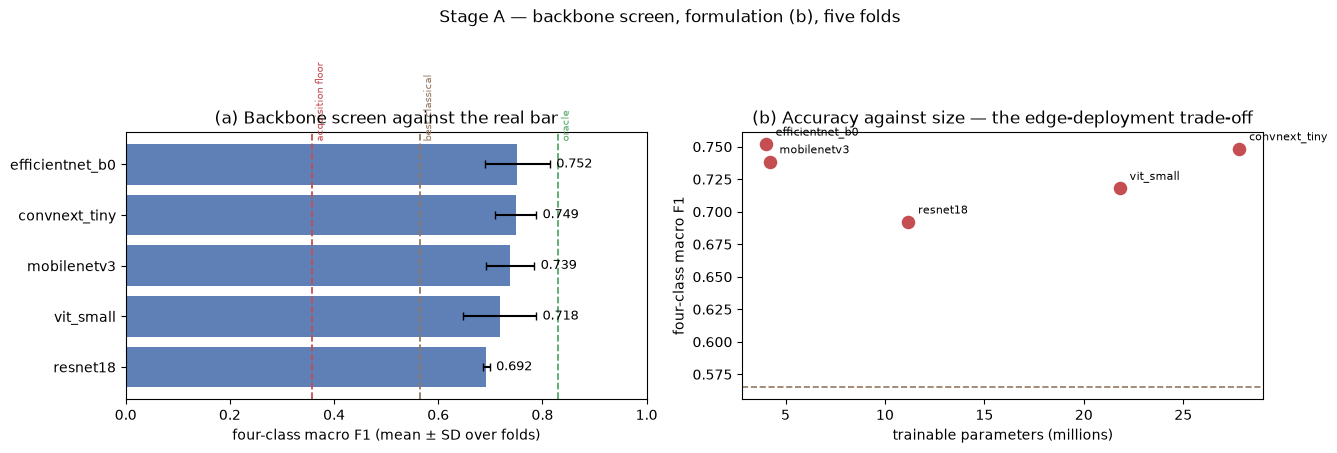

In [8]:
if RUNS_CSV.exists():
    runs = pd.read_csv(RUNS_CSV)
    a = runs[runs["tag"].eq("stageA")] if "tag" in runs.columns else runs.iloc[0:0]
else:
    a = pd.DataFrame()

if len(a):
    agg = (a.groupby("backbone")
             .agg(folds=("fold", "nunique"),
                  macro_f1=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std"),
                  binary_f1=("macro_f1_binary", "mean"),
                  bal_acc=("balanced_acc", "mean"),
                  params_m=("params_m", "mean"), vram_gb=("peak_vram_gb", "mean"),
                  min_per_fold=("seconds", lambda s: s.mean() / 60),
                  epochs=("epochs_run", "mean"))
             .sort_values("macro_f1", ascending=False).round(4))
    agg.to_csv(TAB_DIR / "t01_stage_a_backbones.csv")
    print(agg.to_string())

    top2 = list(agg.index[:2])
    print(f"\nTop two backbones carried into Stage B: {top2}")
    (OUT / "stage_a_selection.json").write_text(json.dumps(
        {"top2": top2, "table": agg.reset_index().to_dict("records"),
         "targets": TARGETS}, indent=2, default=str))

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
    ax = axes[0]
    ax.barh(agg.index, agg["macro_f1"], xerr=agg["macro_f1_sd"].fillna(0),
            color="#4C72B0", alpha=0.9, capsize=3)
    for name, x, lab, col in [("floor", TARGETS["acquisition_floor_4class"],
                               "acquisition floor", "#C44E52"),
                              ("classical", TARGETS["best_classical_4class"],
                               "best classical", "#937860"),
                              ("oracle", TARGETS["oracle_4class"], "oracle", "#55A868")]:
        ax.axvline(x, ls="--", lw=1.3, color=col)
        ax.text(x + 0.006, -0.45, lab, fontsize=7.5, color=col, rotation=90, va="bottom")
    for i, (m, s) in enumerate(zip(agg["macro_f1"], agg["macro_f1_sd"].fillna(0))):
        ax.text(m + s + 0.012, i, f"{m:.3f}", va="center", fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, 1.0)
    ax.set_xlabel("four-class macro F1 (mean ± SD over folds)")
    ax.set_title("(a) Backbone screen against the real bar")

    ax = axes[1]
    ax.scatter(agg["params_m"], agg["macro_f1"], s=120, color="#C44E52",
               edgecolor="white", linewidth=1.2, zorder=3)
    for b in agg.index:
        ax.annotate(b, (agg.loc[b, "params_m"], agg.loc[b, "macro_f1"]),
                    xytext=(7, 6), textcoords="offset points", fontsize=8)
    ax.axhline(TARGETS["best_classical_4class"], ls="--", color="#937860", lw=1.2)
    ax.set_xlabel("trainable parameters (millions)"); ax.set_ylabel("four-class macro F1")
    ax.set_title("(b) Accuracy against size — the edge-deployment trade-off")
    fig.suptitle("Stage A — backbone screen, formulation (b), five folds", y=1.02, fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "01_stage_a_backbones.png", bbox_inches="tight")
    plt.show()
else:
    print("no Stage A runs recorded yet")

In [9]:
if len(a):
    L = ["=" * 70, "NOTEBOOK 05 DIGEST -- STAGE A BACKBONE SCREEN", "=" * 70,
         f"generated: {datetime.now().isoformat(timespec='seconds')}",
         f"resolution {TRAIN_SIDE}px | policy {POLICY} | effective batch {EFFECTIVE_BATCH}", "",
         "TARGETS", f"   acquisition floor  4cls {TARGETS['acquisition_floor_4class']}  "
                    f"bin {TARGETS['acquisition_floor_binary']}",
         f"   best classical     4cls {TARGETS['best_classical_4class']}  "
         f"bin {TARGETS['best_classical_binary']}",
         f"   oracle             4cls {TARGETS['oracle_4class']}", "",
         "STAGE A RESULTS (mean over folds)"]
    for b, r in agg.iterrows():
        beat = "BEATS classical" if r["macro_f1"] > TARGETS["best_classical_4class"] else \
               ("above floor" if r["macro_f1"] > TARGETS["acquisition_floor_4class"]
                else "BELOW ACQUISITION FLOOR")
        L.append(f"   {b:<16s} 4cls {r['macro_f1']:.4f} ± {0 if pd.isna(r['macro_f1_sd']) else r['macro_f1_sd']:.4f}  "
                 f"bin {r['binary_f1']:.4f}  {r['params_m']:.1f}M  "
                 f"{r['vram_gb']:.2f}GB  {r['min_per_fold']:.1f}min/fold  [{beat}]")
    L += ["", f"TOP TWO FOR STAGE B: {top2}", "=" * 70]
    digest = "\n".join(L)
    (OUT / "digest.txt").write_text(digest)
    print(digest)

NOTEBOOK 05 DIGEST -- STAGE A BACKBONE SCREEN
generated: 2026-10-08T10:44:12
resolution 384px | policy medium | effective batch 32

TARGETS
   acquisition floor  4cls 0.357  bin 0.666
   best classical     4cls 0.565  bin 0.77
   oracle             4cls 0.829

STAGE A RESULTS (mean over folds)
   efficientnet_b0  4cls 0.7521 ± 0.0624  bin 0.8588  4.0M  4.38GB  2.8min/fold  [BEATS classical]
   convnext_tiny    4cls 0.7485 ± 0.0398  bin 0.8555  27.8M  3.57GB  1.3min/fold  [BEATS classical]
   mobilenetv3      4cls 0.7385 ± 0.0461  bin 0.8527  4.2M  2.32GB  2.1min/fold  [BEATS classical]
   vit_small        4cls 0.7181 ± 0.0701  bin 0.8587  21.8M  2.17GB  1.1min/fold  [BEATS classical]
   resnet18         4cls 0.6922 ± 0.0069  bin 0.7975  11.2M  1.44GB  1.2min/fold  [BEATS classical]

TOP TWO FOR STAGE B: ['efficientnet_b0', 'convnext_tiny']
